# 05 — Controlled curvature: plane versus known-core quadratic reconstruction

**Execution:** select the project's Python kernel, then use **Restart Kernel** and **Run All** from the top. Saved outputs do not restore live variables. Section 3 creates `BASE_CASES` and `INPUTS`; Section 6 creates `results`. Later sections require those earlier cells to have run in the current kernel. Each full run creates a new results directory.

## 1. Question and scope

When a shower front is curved, does explicitly fitting curvature improve reconstruction of its **known synthetic direction**, rather than merely lower its timing residuals?

We compare the unchanged plane fitter with a new **known-core** quadratic fitter, using both timing-uncertainty and uniform weights. Neither fitter receives the true direction or curvature. The curved fitter **does receive the true core in the primary experiment**; this is a stated information advantage, not an independently reconstructed core.

This is a controlled timing simulation, not a particle-cascade or detector-response simulation. No real Auger event, published direction, or published core enters this notebook. Results do not establish that our real-event high chi-square has been explained or that we outperform Auger.

### Physics before code

Let $\mathbf u$ be the downward unit propagation vector, $\mathbf r_c$ the core and $\mathbf d_i=\mathbf r_i-\mathbf r_c$. The transverse distance is

$$
\rho_i=\|\mathbf d_i\times\mathbf u\|,
\qquad
t_i=t_c+\frac{\mathbf d_i\cdot\mathbf u}{c}
+A\left(\frac{\rho_i}{1000\ {\rm m}}\right)^2+\epsilon_i .
$$

$A\ge0$ is the curvature delay **in ns at 1 km perpendicular to the axis**. Ground distance and perpendicular distance are not interchangeable. The source generator uses $\kappa=A/10^6$ in ns/m². At $A=0$ this is exactly the plane model. For positive $A$, the local equivalent spherical radius is $R=10^6/(2cA)$; we are not calibrating that radius to a real shower.

This timing form corresponds to the paraboloidal approximation in [Auger, JINST 15 (2020) P10021, §5.1, Eq. 5.3](https://arxiv.org/pdf/2007.09035), with the propagation-vector sign and time units converted. Implementing the equation does **not** reproduce the complete Auger reconstruction.

The curved fitter optimizes two direction parameters, core time, and $A$. It recomputes $\rho_i$ from the **trial** direction during optimization. Its nominal residual degrees of freedom are $N-4$, versus $N-3$ for the plane. At the $A=0$ boundary, the ordinary interior chi-square interpretation is not exact. Uniform fitting with heterogeneous uncertainties also does not minimize physical chi-square.

## 2. Freeze the protocol before examining results

The primary grid uses 16 base cases: two flat geometry families, 12/24 stations, two direction pairs, and centred/offset cores. Five curvature levels and 100 Gaussian-noise realizations give 8,000 synthetic datasets and 32,000 fit attempts. Four fixed layouts are reused across direction/core cases; these are not 8,000 independent shower geometries.

The symmetric geometry has opposite station pairs and varying radii, with equal uncertainties within each opposite pair. This supplies a useful parity control. All profiles have RMS uncertainty 10 ns. Exact trials and small smoke checks precede the main experiment.

Seeds, inputs, options, software versions, source hashes, optimizer attempts, failures and generated noise are archived. The same noise vector is used for all curvature levels and all methods within a base-case/trial pair. An extra, separately seeded stress study tests core offsets and a translating spherical-cap front. We do not choose settings to force chi-square toward one.


In [7]:
from __future__ import annotations

import gzip
import json
import platform
import subprocess
import time
from dataclasses import asdict
from datetime import UTC, datetime
from hashlib import sha256
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import Markdown, display

from auger_reco.physics import curved_front, plane_front
from auger_reco.physics.quadratic_front import quadratic_front_times_ns

PROJECT_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "src/auger_reco").is_dir()
)
NOTEBOOK_PATH = PROJECT_ROOT / "notebooks/05_benchmark_curved_front.ipynb"
MASTER_SEED = 20261010
TRIALS = 100
BOOTSTRAP_RESAMPLES = 2000
CURVATURE_LEVELS_NS = (0.0, 25.0, 50.0, 100.0, 200.0)
DIRECTIONS_DEG = ((20.0, 20.0), (55.0, 110.0))
CORE_POSITIONS_M = {"centred": (0.0, 0.0, 0.0), "offset": (600.0, -400.0, 0.0)}
TRUE_CORE_TIME_NS = 100_000.0
ANGLE_TOLERANCE_DEG = 1.0e-5
TIME_TOLERANCE_NS = 1.0e-4
CURVATURE_TOLERANCE_NS = 1.0e-3
OBJECTIVE_RELATIVE_TOLERANCE = 1.0e-6
PLANE_OPTIONS = plane_front.PlaneFrontFitOptions(minimum_stations=6)
CURVED_OPTIONS = curved_front.QuadraticFrontFitOptions()
METHODS = tuple(product(("plane", "quadratic"), ("timing", "uniform")))
run_id = datetime.now(UTC).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR = PROJECT_ROOT / "reports/results" / f"synthetic_curvature_{run_id}"
RUN_DIR.mkdir(parents=True, exist_ok=False)


def json_ready(value):
    """Encode arrays and diagnostics; undefined/infinite diagnostics become null."""
    if isinstance(value, dict):
        return {str(key): json_ready(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_ready(item) for item in value]
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, np.generic):
        return json_ready(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


def save_json(name, value):
    (RUN_DIR / name).write_text(
        json.dumps(json_ready(value), indent=2, allow_nan=False) + "\n", encoding="utf-8"
    )


def require_notebook_state(section, *names):
    """Explain skipped prerequisites before downstream cells write artifacts."""
    missing = [name for name in names if name not in globals()]
    if missing:
        raise RuntimeError(
            f"{section} is missing prerequisites: {', '.join(missing)}. "
            "Restart the kernel and choose Run All from the top. "
            "Saved tables and plots do not restore variables into a new kernel."
        )


def keyed_rng(stream, key, trial=0):
    """Hash identity, not loop order, so reordering cases never changes their noise."""
    digest = sha256(key.encode("utf-8")).digest()
    words = np.frombuffer(digest, dtype="<u4").tolist()
    return np.random.Generator(
        np.random.PCG64(np.random.SeedSequence([MASTER_SEED, stream, *words, trial]))
    )


configuration = {
    "study_version": 1,
    "master_seed": MASTER_SEED,
    "trials": TRIALS,
    "bootstrap_resamples": BOOTSTRAP_RESAMPLES,
    "curvature_levels_ns": CURVATURE_LEVELS_NS,
    "directions_deg": DIRECTIONS_DEG,
    "core_positions_m": CORE_POSITIONS_M,
    "rms_array_radius_m": 1000.0,
    "rms_timing_uncertainty_ns": 10.0,
    "true_core_time_ns": TRUE_CORE_TIME_NS,
    "methods": METHODS,
    "plane_options": asdict(PLANE_OPTIONS),
    "quadratic_options": asdict(CURVED_OPTIONS),
    "angle_tolerance_deg": ANGLE_TOLERANCE_DEG,
    "time_tolerance_ns": TIME_TOLERANCE_NS,
    "curvature_tolerance_ns": CURVATURE_TOLERANCE_NS,
    "objective_relative_tolerance": OBJECTIVE_RELATIVE_TOLERANCE,
    "streams": {"layout": 1, "uncertainty": 2, "main": 3, "smoke": 4, "bootstrap": 5, "stress": 6},
    "stress_case": {
        "geometry": "irregular",
        "number_of_stations": 24,
        "zenith_deg": 55.0,
        "azimuth_deg": 110.0,
        "core_label": "offset",
        "delay_at_1km_ns": 100.0,
    },
    "stress_assumed_core_shifts_m": [
        [0, 0, 0],
        [100, 0, 0],
        [-100, 0, 0],
        [0, 100, 0],
        [0, -100, 0],
    ],
    "python": platform.python_version(),
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "pandas": pd.__version__,
    "git_head": subprocess.check_output(
        ["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, text=True
    ).strip(),
    "git_status": subprocess.check_output(
        ["git", "status", "--short"], cwd=PROJECT_ROOT, text=True
    ),
    "source_sha256": {},
    "assumption": "Known true core supplied to quadratic fits in primary grid.",
}
for relative in (
    "src/auger_reco/physics/plane_front.py",
    "src/auger_reco/physics/quadratic_front.py",
    "src/auger_reco/physics/curved_front.py",
    "notebooks/05_benchmark_curved_front.ipynb",
):
    content = (PROJECT_ROOT / relative).read_bytes()
    configuration["source_sha256"][relative] = sha256(content).hexdigest()
    (RUN_DIR / Path(relative).name).write_bytes(content)
save_json("configuration.json", configuration)
save_json("run_status.json", {"state": "configured"})
print(f"Artifacts: {RUN_DIR}")

Artifacts: /home/abdul_samad/projects/auger-direction-reconstruction/reports/results/synthetic_curvature_20261010T190421_183127Z


## 3. Build known showers without using the fitting code to generate directions

A NumPy array stores one station position per row: shape $(N,3)$. Positions are centred and rescaled to 1 km RMS horizontal radius. This fixes the array extent rather than making denser arrays automatically larger. We retain the complete coordinates, not only the seed.

For the symmetric control, we concatenate a random half-layout with its negative. The radial spread prevents a vertical, single-ring degeneracy in which every station receives the same curvature delay and that delay is indistinguishable from a time offset.

The cross product independently computes the true transverse distances for checking generation and for labelled diagnostic plots. Those true distances are never sent to either fitter.


In [8]:
BASE_CASES = []
for geometry, count, direction, core_label in product(
    ("symmetric", "irregular"), (12, 24), DIRECTIONS_DEG, CORE_POSITIONS_M
):
    theta, phi = direction
    case = {
        "geometry": geometry,
        "number_of_stations": count,
        "zenith_deg": theta,
        "azimuth_deg": phi,
        "core_label": core_label,
    }
    case["case_id"] = f"{geometry}_n{count}_theta{theta:g}_phi{phi:g}_{core_label}"
    BASE_CASES.append(case)


def generate_case(case):
    layout_key = f"{case['geometry']}_n{case['number_of_stations']}"
    rng = keyed_rng(1, layout_key)
    count = case["number_of_stations"]
    half_count = count // 2 if case["geometry"] == "symmetric" else count
    azimuth = rng.uniform(0.0, 2.0 * np.pi, half_count)
    radius = np.sqrt(rng.uniform(0.05, 1.0, half_count))
    xy = np.column_stack((radius * np.cos(azimuth), radius * np.sin(azimuth)))
    if case["geometry"] == "symmetric":
        xy = np.concatenate((xy, -xy))
    xy -= xy.mean(axis=0)
    xy *= 1000.0 / np.sqrt(np.mean(np.sum(xy**2, axis=1)))
    positions = np.column_stack((xy, np.zeros(count)))
    scales = keyed_rng(2, layout_key).permutation(np.linspace(0.5, 2.0, half_count))
    if case["geometry"] == "symmetric":
        scales = np.concatenate((scales, scales))
    sigma = 10.0 * scales / np.sqrt(np.mean(scales**2))
    theta, phi = np.deg2rad([case["zenith_deg"], case["azimuth_deg"]])
    sky = np.array([np.sin(theta) * np.cos(phi), np.sin(theta) * np.sin(phi), np.cos(theta)])
    core = np.array(CORE_POSITIONS_M[case["core_label"]])
    rho = np.linalg.norm(np.cross(positions - core, -sky), axis=1)
    for value in (positions, sigma, sky, core, rho):
        value.setflags(write=False)
    return {"positions": positions, "sigma": sigma, "sky": sky, "core": core, "rho": rho}


INPUTS = {case["case_id"]: generate_case(case) for case in BASE_CASES}
manifest = []
for case in BASE_CASES:
    data = INPUTS[case["case_id"]]
    manifest.append({**case, **data})
save_json("case_manifest.json", manifest)
display(pd.DataFrame(BASE_CASES))
assert len(BASE_CASES) == 16


def exact_times(data, delay_ns):
    """Convert delay at 1 km to the generator's coefficient in ns/m²."""
    generated = quadratic_front_times_ns(
        data["positions"], -data["sky"], data["core"], TRUE_CORE_TIME_NS, delay_ns / 1_000_000.0
    )
    # Independent cross-product expression checks signs, units, and projection.
    expected = (
        TRUE_CORE_TIME_NS
        - (data["positions"] - data["core"]) @ data["sky"] / 0.299792458
        + delay_ns * (data["rho"] / 1000.0) ** 2
    )
    np.testing.assert_allclose(generated, expected, rtol=0.0, atol=1.0e-8)
    return generated

,geometry,number_of_stations,zenith_deg,azimuth_deg,core_label,case_id
0,symmetric,12,20.0,20.0,centred,symmetric_n12_theta20_phi20_centred
1,symmetric,12,20.0,20.0,offset,symmetric_n12_theta20_phi20_offset
2,symmetric,12,55.0,110.0,centred,symmetric_n12_theta55_phi110_centred
3,symmetric,12,55.0,110.0,offset,symmetric_n12_theta55_phi110_offset
4,symmetric,24,20.0,20.0,centred,symmetric_n24_theta20_phi20_centred
5,symmetric,24,20.0,20.0,offset,symmetric_n24_theta20_phi20_offset
6,symmetric,24,55.0,110.0,centred,symmetric_n24_theta55_phi110_centred
7,symmetric,24,55.0,110.0,offset,symmetric_n24_theta55_phi110_offset
8,irregular,12,20.0,20.0,centred,irregular_n12_theta20_phi20_centred
9,irregular,12,20.0,20.0,offset,irregular_n12_theta20_phi20_offset


## 4. Fit without handing the solver its answer

The fitting wrapper passes positions, observed times, and uncertainties to both methods. Only the quadratic fit additionally receives an explicitly supplied core. True sky direction is accessed **after fitting**, solely to measure angular error.

Residuals follow $e_i=t_i^{\rm obs}-t_i^{\rm pred}$ and $q_i=e_i/\sigma_i$. Positive residual means the station was reached later than predicted. Timing weighting minimizes $\sum q_i^2$; uniform weighting minimizes $\sum e_i^2$. Physical chi-square is still calculated with the stated uncertainties for both.

We retain expected numerical/geometry failures and every optimizer attempt. Invalid outputs are recorded as failures, never assigned zero angular error. An unexpected programming error stops execution. The main comparison is conditional on both fits succeeding; attempt and success counts remain visible.


In [9]:
EXPECTED_FAILURES = (
    plane_front.DegenerateStationGeometryError,
    plane_front.PlaneFrontInitializationError,
    plane_front.PlaneFrontOptimizationError,
    curved_front.QuadraticFrontGeometryError,
    curved_front.QuadraticFrontOptimizationError,
)


def run_fit(case, data, observed, delay_ns, model, weighting, trial, stage, assumed_core=None):
    record = {
        **case,
        "stage": stage,
        "trial": trial,
        "delay_at_1km_ns": delay_ns,
        "model": model,
        "weighting": weighting,
        "success": False,
        "angular_error_deg": np.nan,
        "chi_square": np.nan,
        "nominal_reduced_chi_square": np.nan,
        "rms_residual_ns": np.nan,
        "objective_sum_squares": np.nan,
        "fitted_delay_at_1km_ns": np.nan,
        "curvature_error_ns": np.nan,
        "curvature_at_boundary": False,
    }
    details = {}
    try:
        if model == "plane":
            fit = plane_front.fit_plane_front(
                data["positions"],
                observed,
                data["sigma"],
                weighting=weighting,
                options=PLANE_OPTIONS,
            )
        else:
            fit = curved_front.fit_quadratic_front(
                data["positions"],
                observed,
                data["sigma"],
                core_position_m=data["core"] if assumed_core is None else assumed_core,
                weighting=weighting,
                options=CURVED_OPTIONS,
            )
    except EXPECTED_FAILURES as error:
        record["failure_type"] = type(error).__name__
        record["failure_message"] = str(error)
        details["attempts"] = [asdict(attempt) for attempt in getattr(error, "attempts", ())]
        details["initializer_rejections"] = getattr(error, "rejected_initializers", ())
        return record, details, None

    details = {
        "attempts": [asdict(attempt) for attempt in fit.optimizer_attempts],
        "quality_flags": fit.quality_flags,
        "sky_direction": fit.sky_direction,
        "options": asdict(fit.options),
    }
    expected_df = len(observed) - (3 if model == "plane" else 4)
    arrays_valid = all(
        np.shape(value) == observed.shape and np.isfinite(value).all()
        for value in (fit.predicted_times_ns, fit.residuals_ns, fit.standardized_residuals)
    )
    scalar_values = [
        fit.chi_square,
        fit.reduced_chi_square,
        fit.rms_residual_ns,
        fit.objective_sum_squares,
    ]
    valid = (
        arrays_valid
        and np.isfinite(scalar_values).all()
        and np.all(np.array(scalar_values) >= 0.0)
        and np.shape(fit.sky_direction) == (3,)
        and np.isfinite(fit.sky_direction).all()
        and np.isclose(np.linalg.norm(fit.sky_direction), 1.0, atol=1e-10, rtol=0)
        and fit.sky_direction[2] > 0
        and fit.number_of_stations == len(observed)
        and fit.degrees_of_freedom == expected_df
        and fit.final_jacobian_rank == (3 if model == "plane" else 4)
        and np.allclose(fit.residuals_ns, observed - fit.predicted_times_ns, rtol=0, atol=1e-7)
        and np.allclose(
            fit.standardized_residuals, fit.residuals_ns / data["sigma"], rtol=1e-8, atol=1e-8
        )
        and np.isclose(fit.chi_square, np.sum(fit.standardized_residuals**2), rtol=1e-8, atol=1e-8)
    )
    if not valid:
        record["failure_type"] = "InvalidFitDiagnostics"
        record["failure_message"] = "Output validation failed."
        return record, details, None
    record.update(
        {
            "success": True,
            "angular_error_deg": plane_front.angular_separation_deg(fit.sky_direction, data["sky"]),
            "chi_square": fit.chi_square,
            "nominal_reduced_chi_square": fit.reduced_chi_square,
            "rms_residual_ns": fit.rms_residual_ns,
            "objective_sum_squares": fit.objective_sum_squares,
        }
    )
    if model == "quadratic":
        if not np.isfinite(fit.delay_at_1km_ns) or fit.delay_at_1km_ns < 0:
            record["success"] = False
            record["failure_type"] = "InvalidCurvature"
            return record, details, None
        record["fitted_delay_at_1km_ns"] = fit.delay_at_1km_ns
        record["curvature_error_ns"] = fit.delay_at_1km_ns - delay_ns
        record["curvature_at_boundary"] = fit.delay_at_1km_ns <= CURVATURE_TOLERANCE_NS
    return record, details, fit


def objective_order_ok(records):
    """Curvature includes the plane at A=0; compare the SAME minimized objective."""
    checks = []
    for weighting in ("timing", "uniform"):
        selected = {row["model"]: row for row in records if row["weighting"] == weighting}
        if all(row["success"] for row in selected.values()) and len(selected) == 2:
            baseline = selected["plane"]["objective_sum_squares"]
            curved = selected["quadratic"]["objective_sum_squares"]
            checks.append(curved <= baseline + OBJECTIVE_RELATIVE_TOLERANCE * max(1.0, baseline))
    return all(checks)

## 5. Noiseless controls before Monte Carlo

Without noise, the matching curved model must recover direction, times, and injected curvature within explicit numerical tolerances. At zero curvature both fitters must recover the plane.

A central symmetric array offers a subtle control: a quadratic delay is even under $\mathbf r\mapsto-\mathbf r$, whereas the plane's directional timing gradient is odd. With opposite-pair weights, the plane can recover the direction yet retain a large timing mismatch. This is why a high chi-square is a model-check warning, not automatically proof of a wrong direction.

We save the exact-data results and all attempts before proceeding. The separate smoke stream exercises noisy paths without consuming the main experiment's random numbers.


In [10]:
require_notebook_state(
    "Section 5", "BASE_CASES", "INPUTS", "exact_times", "run_fit", "objective_order_ok"
)

exact_records = []
with gzip.open(RUN_DIR / "exact_optimizer_attempts.jsonl.gz", "wt", encoding="utf-8") as log:
    for case in BASE_CASES:
        data = INPUTS[case["case_id"]]
        for delay_ns in CURVATURE_LEVELS_NS:
            observed = exact_times(data, delay_ns)
            observed.setflags(write=False)
            group = []
            for model, weighting in METHODS:
                row, details, fit = run_fit(
                    case, data, observed, delay_ns, model, weighting, -1, "noiseless"
                )
                if fit is not None:
                    row["max_absolute_residual_ns"] = float(np.max(np.abs(fit.residuals_ns)))
                exact_records.append(row)
                group.append(row)
                log.write(
                    json.dumps(json_ready({"metrics": row, **details}), allow_nan=False) + "\n"
                )
            assert objective_order_ok(group), "Noiseless nested objective ordering failed."

exact_results = pd.DataFrame(exact_records)
exact_results.to_csv(RUN_DIR / "noiseless_results.csv", index=False)
assert exact_results["success"].all(), "Investigate failed exact fits before Monte Carlo."
matching = exact_results.loc[
    (exact_results["model"] == "quadratic") | (exact_results["delay_at_1km_ns"] == 0)
]
assert matching["angular_error_deg"].max() < ANGLE_TOLERANCE_DEG
assert matching["max_absolute_residual_ns"].max() < TIME_TOLERANCE_NS
assert (
    exact_results.loc[exact_results["model"] == "quadratic", "curvature_error_ns"].abs().max()
    < CURVATURE_TOLERANCE_NS
)
parity = exact_results.loc[
    (exact_results["geometry"] == "symmetric")
    & (exact_results["core_label"] == "centred")
    & (exact_results["model"] == "plane")
]
assert parity["angular_error_deg"].max() < ANGLE_TOLERANCE_DEG

smoke_rows = []
for case in (BASE_CASES[0], BASE_CASES[-1]):
    data = INPUTS[case["case_id"]]
    for delay_ns in (0.0, 100.0):
        noise = keyed_rng(4, case["case_id"]).normal(0.0, data["sigma"])
        observed = exact_times(data, delay_ns) + noise
        observed.setflags(write=False)
        group = []
        for model, weighting in METHODS:
            row, _, _ = run_fit(case, data, observed, delay_ns, model, weighting, 0, "smoke")
            smoke_rows.append(row)
            group.append(row)
        assert objective_order_ok(group)
save_json("smoke_checks.json", smoke_rows)
assert all(row["success"] for row in smoke_rows)
save_json(
    "exact_checks.json",
    {
        "fit_count": len(exact_results),
        "all_successful": True,
        "matching_max_angle_deg": matching["angular_error_deg"].max(),
        "matching_max_timing_residual_ns": matching["max_absolute_residual_ns"].max(),
        "curvature_max_absolute_error_ns": exact_results.loc[
            exact_results["model"] == "quadratic", "curvature_error_ns"
        ]
        .abs()
        .max(),
        "parity_max_plane_angle_deg": parity["angular_error_deg"].max(),
    },
)
print(f"Passed {len(exact_results)} noiseless fits and {len(smoke_rows)} noisy smoke fits.")
display(
    parity.loc[
        parity["delay_at_1km_ns"] == 100,
        ["case_id", "weighting", "angular_error_deg", "nominal_reduced_chi_square"],
    ]
)

Passed 320 noiseless fits and 16 noisy smoke fits.


,case_id,weighting,angular_error_deg,nominal_reduced_chi_square
12,symmetric_n12_theta20_phi20_centred,timing,4.550138e-12,27.464753
13,symmetric_n12_theta20_phi20_centred,uniform,3.246708e-14,38.138538
52,symmetric_n12_theta55_phi110_centred,timing,7.761466e-14,23.453492
53,symmetric_n12_theta55_phi110_centred,uniform,1.303057e-13,41.194449
92,symmetric_n24_theta20_phi20_centred,timing,5.073489e-14,31.147752
93,symmetric_n24_theta20_phi20_centred,uniform,2.905522e-14,37.136055
132,symmetric_n24_theta55_phi110_centred,timing,3.398426e-12,17.799033
133,symmetric_n24_theta55_phi110_centred,uniform,6.323227e-14,19.505441


## 6. Paired Gaussian-noise experiment

For trial $j$, generate one vector $\epsilon_{ij}\sim\mathcal N(0,\sigma_i^2)$. Adding exactly that vector to every curvature level controls random variation while testing the effect of changing $A$. It also ensures every method sees the same observations.

The loop logs every attempted fit, including failures, and flushes progress after each base case. Stored noise arrays allow exact replay. No failed trial is replaced with an easier one. An incomplete run is not a final scientific result.


In [11]:
require_notebook_state(
    "Section 6", "BASE_CASES", "INPUTS", "exact_times", "run_fit", "exact_results", "smoke_rows"
)

all_records = []
noise_archive = {}
nested_violations = []
started = time.perf_counter()
save_json("run_status.json", {"state": "running", "completed_base_cases": 0})
try:
    with gzip.open(RUN_DIR / "optimizer_attempts.jsonl.gz", "wt", encoding="utf-8") as log:
        for case_index, case in enumerate(BASE_CASES):
            data = INPUTS[case["case_id"]]
            noise_matrix = np.stack(
                [
                    keyed_rng(3, case["case_id"], trial).normal(0.0, data["sigma"])
                    for trial in range(TRIALS)
                ]
            )
            noise_archive[case["case_id"]] = noise_matrix
            for trial, noise in enumerate(noise_matrix):
                for delay_ns in CURVATURE_LEVELS_NS:
                    observed = exact_times(data, delay_ns) + noise
                    observed.setflags(write=False)
                    group = []
                    for model, weighting in METHODS:
                        row, details, _ = run_fit(
                            case, data, observed, delay_ns, model, weighting, trial, "main"
                        )
                        all_records.append(row)
                        group.append(row)
                        log.write(
                            json.dumps(json_ready({"metrics": row, **details}), allow_nan=False)
                            + "\n"
                        )
                    if not objective_order_ok(group):
                        nested_violations.append(
                            {
                                "case_id": case["case_id"],
                                "trial": trial,
                                "delay_at_1km_ns": delay_ns,
                            }
                        )
            log.flush()
            save_json(
                "run_status.json",
                {
                    "state": "running",
                    "completed_base_cases": case_index + 1,
                    "recorded_fits": len(all_records),
                },
            )
            print(f"Completed {case_index + 1}/{len(BASE_CASES)} base cases.", flush=True)
except Exception as error:
    save_json(
        "run_status.json",
        {"state": "interrupted", "error": repr(error), "recorded_fits": len(all_records)},
    )
    raise
finally:
    np.savez_compressed(RUN_DIR / "timing_noise_draws.npz", **noise_archive)

results = pd.DataFrame(all_records)
results.to_csv(RUN_DIR / "fit_metrics.csv.gz", index=False, compression="gzip")
assert len(results) == len(BASE_CASES) * len(CURVATURE_LEVELS_NS) * TRIALS * len(METHODS)
assert not results.duplicated(["case_id", "delay_at_1km_ns", "trial", "model", "weighting"]).any()
save_json(
    "numerical_controls.json",
    {
        "nested_objective_violations": nested_violations,
        "fit_attempts": len(results),
        "successful_fits": int(results["success"].sum()),
        "runtime_seconds": time.perf_counter() - started,
    },
)
if nested_violations:
    raise RuntimeError("Nested objective ordering failed; artifacts retained for investigation.")
save_json("run_status.json", {"state": "main_complete", "fit_attempts": len(results)})
display(results.groupby(["model", "weighting"])["success"].agg(["size", "sum"]))

Completed 1/16 base cases.
Completed 2/16 base cases.
Completed 3/16 base cases.
Completed 4/16 base cases.
Completed 5/16 base cases.
Completed 6/16 base cases.
Completed 7/16 base cases.
Completed 8/16 base cases.
Completed 9/16 base cases.
Completed 10/16 base cases.
Completed 11/16 base cases.
Completed 12/16 base cases.
Completed 13/16 base cases.
Completed 14/16 base cases.
Completed 15/16 base cases.
Completed 16/16 base cases.


size   sum
model     weighting            
plane     timing     8000  8000
          uniform    8000  8000
quadratic timing     8000  8000
          uniform    8000  8000

## 7. Separate accuracy, residual agreement, and numerical success

Angular error measures recovery of known truth. Chi-square measures disagreement relative to the supplied timing uncertainties. These are different diagnostics.

For each fixed case and curvature level, compute paired angular improvement

$$
\Delta_j=\alpha_{{\rm plane},j}-\alpha_{{\rm curved},j}.
$$

Positive $\Delta$ favours the curved model. Bootstrap **trial pairs** within that case to obtain a percentile interval for its median. These are conditional Monte Carlo intervals for this setup, not confidence regions on a real event, a population survey, or simultaneous claims across the grid. With only 100 draws, p95 is exploratory (roughly five upper-tail draws).

We also report curvature bias/RMSE and the fraction with fitted $A\le10^{-3}$ ns, our numerical boundary threshold. Positive fitted curvature on planar data is not automatically a detection. No naive one-degree-of-freedom significance test is used at this parameter boundary.


In [12]:
require_notebook_state("Section 7", "results", "noise_archive")

summary_rows = []
group_keys = [
    "case_id",
    "geometry",
    "number_of_stations",
    "zenith_deg",
    "azimuth_deg",
    "core_label",
    "delay_at_1km_ns",
    "model",
    "weighting",
]
for keys, frame in results.groupby(group_keys, sort=True):
    valid = frame.loc[frame["success"]]
    errors = valid["angular_error_deg"].to_numpy()
    curvature_errors = valid["curvature_error_ns"].dropna().to_numpy()
    row = dict(zip(group_keys, keys, strict=True))
    row.update(
        {
            "attempts": len(frame),
            "successes": len(valid),
            "failures": len(frame) - len(valid),
            "median_error_deg": np.median(errors) if len(errors) else np.nan,
            "p68_error_deg": np.quantile(errors, 0.68) if len(errors) else np.nan,
            "p95_error_deg": np.quantile(errors, 0.95) if len(errors) else np.nan,
            "mean_nominal_reduced_chi_square": valid["nominal_reduced_chi_square"].mean(),
            "mean_rms_residual_ns": valid["rms_residual_ns"].mean(),
            "curvature_bias_ns": np.mean(curvature_errors) if len(curvature_errors) else np.nan,
            "curvature_rmse_ns": (
                np.sqrt(np.mean(curvature_errors**2)) if len(curvature_errors) else np.nan
            ),
            "curvature_boundary_fraction": (
                valid["curvature_at_boundary"].mean() if row["model"] == "quadratic" else np.nan
            ),
        }
    )
    summary_rows.append(row)
method_summary = pd.DataFrame(summary_rows)
method_summary.to_csv(RUN_DIR / "summary_by_scenario.csv", index=False)

paired_rows = []
paired_trial_frames = []
for keys, frame in results.groupby(["case_id", "delay_at_1km_ns", "weighting"], sort=True):
    plane = frame.loc[frame["model"] == "plane"].set_index("trial")
    quadratic = frame.loc[frame["model"] == "quadratic"].set_index("trial")
    assert plane.index.equals(quadratic.index)
    complete = plane["success"] & quadratic["success"]
    delta = (
        plane.loc[complete, "angular_error_deg"] - quadratic.loc[complete, "angular_error_deg"]
    ).to_numpy()
    lower = upper = np.nan
    if len(delta) >= 20:
        rng = keyed_rng(5, json.dumps(keys))
        indices = rng.integers(0, len(delta), size=(BOOTSTRAP_RESAMPLES, len(delta)))
        lower, upper = np.quantile(np.median(delta[indices], axis=1), [0.025, 0.975])
    paired_rows.append(
        {
            "case_id": keys[0],
            "delay_at_1km_ns": keys[1],
            "weighting": keys[2],
            "attempted_pairs": len(frame) // 2,
            "complete_pairs": len(delta),
            "incomplete_pairs": int((~complete).sum()),
            "median_paired_improvement_deg": np.median(delta) if len(delta) else np.nan,
            "median_ci_low_deg": lower,
            "median_ci_high_deg": upper,
            "curved_win_fraction": np.mean(delta > ANGLE_TOLERANCE_DEG) if len(delta) else np.nan,
            "plane_win_fraction": np.mean(delta < -ANGLE_TOLERANCE_DEG) if len(delta) else np.nan,
            "numerical_tie_fraction": (
                np.mean(np.abs(delta) <= ANGLE_TOLERANCE_DEG) if len(delta) else np.nan
            ),
        }
    )
    paired_trial_frames.append(
        pd.DataFrame(
            {
                "case_id": keys[0],
                "delay_at_1km_ns": keys[1],
                "weighting": keys[2],
                "trial": plane.index[complete],
                "paired_angular_improvement_deg": delta,
            }
        )
    )
paired_summary = pd.DataFrame(paired_rows)
paired_summary.to_csv(RUN_DIR / "paired_summary.csv", index=False)
paired_trials = pd.concat(paired_trial_frames, ignore_index=True)
paired_trials.to_csv(RUN_DIR / "paired_trial_results.csv.gz", index=False, compression="gzip")
# Each scenario gets equal weight here; this is descriptive, not a population estimate.
descriptive = method_summary.groupby(["delay_at_1km_ns", "model", "weighting"]).agg(
    median_of_case_medians_deg=("median_error_deg", "median"),
    mean_of_case_mean_chi_square=("mean_nominal_reduced_chi_square", "mean"),
    failures=("failures", "sum"),
)
descriptive.to_csv(RUN_DIR / "descriptive_grid_summary.csv")
display(descriptive)

median_of_case_medians_deg  \
delay_at_1km_ns model     weighting                               
0.0             plane     timing                       0.068358   
                          uniform                      0.084831   
                quadratic timing                       0.076106   
                          uniform                      0.095309   
25.0            plane     timing                       0.263781   
                          uniform                      0.260189   
                quadratic timing                       0.081847   
                          uniform                      0.104040   
50.0            plane     timing                       0.492048   
                          uniform                      0.509637   
                quadratic timing                       0.081658   
                          uniform                      0.104081   
100.0           plane     timing                       0.957538   
                          uniform                      1.013402   
                quadratic timing                       0.080966   
                          uniform                      0.104357   
200.0           plane     timing                       1.890178   
                          uniform                      2.017152   
                quadratic timing                       0.079650   
                          uniform                      0.104142   

                                     mean_of_case_mean_chi_square  failures  
delay_at_1km_ns model     weighting                                          
0.0             plane     timing                         0.995925         0  
                          uniform                        1.202590         0  
                quadratic timing                         1.039902         0  
                          uniform                        1.269969         0  
25.0            plane     timing                         3.499449         0  
                          uniform                        4.440354         0  
                quadratic timing                         1.001096         0  
                          uniform                        1.238339         0  
50.0            plane     timing                        10.964979         0  
                          uniform                       14.089027         0  
                quadratic timing                         1.001104         0  
                          uniform                        1.238174         0  
100.0           plane     timing                        40.782063         0  
                          uniform                       52.619095         0  
                quadratic timing                         1.001120         0  
                          uniform                        1.237873         0  
200.0           plane     timing                       159.960316         0  
                          uniform                      206.610125         0  
                quadratic timing                         1.001151         0  
                          uniform                        1.237390         0

## 8. Deliberately break two assumptions

Passing known truth to a generator and fitting the same equation is a correctness test, not sufficient evidence of realism. We therefore add two **preselected**, limited stress tests on one irregular, 24-station, off-centre case:

1. Fit quadratic data using a core shifted by $\pm100$ m along either horizontal axis. This is a deterministic sensitivity test, **not** a claimed distribution of Auger core uncertainty.
2. Generate a translating spherical-cap timing delay independently:

$$
\Delta t_{\rm cap}
=\frac{\rho^2}{c\left(R+\sqrt{R^2-\rho^2}\right)}, \qquad \rho<R.
$$

This is the rationalized form of $(R-\sqrt{R^2-\rho^2})/c$, avoiding subtraction cancellation. It is the cap geometry motivating the quadratic expansion, **not** the distinct expanding-sphere model in Auger Eq. 5.4. The quadratic fitter is deliberately not told the cap formula.

These tests use a separate noise stream and timing weighting only. All conditions share its draws. We report the size of cap–quadratic timing differences: a very small mismatch is only a mild stress test. Known-core timing-only fits do not settle the later problem of independent core estimation.


In [13]:
require_notebook_state("Section 8", "BASE_CASES", "INPUTS", "results", "paired_summary")

stress_spec = configuration["stress_case"]
stress_case = next(
    case
    for case in BASE_CASES
    if all(
        case[key] == stress_spec[key]
        for key in ("geometry", "number_of_stations", "zenith_deg", "azimuth_deg", "core_label")
    )
)
stress_data = INPUTS[stress_case["case_id"]]
stress_delay = stress_spec["delay_at_1km_ns"]
quadratic_exact = exact_times(stress_data, stress_delay)
radius_m = 1_000_000.0 / (2.0 * plane_front.C_M_PER_NS * stress_delay)
assert np.all(stress_data["rho"] < radius_m)
cap_delay = stress_data["rho"] ** 2 / (
    plane_front.C_M_PER_NS * (radius_m + np.sqrt(radius_m**2 - stress_data["rho"] ** 2))
)
cap_exact = (
    TRUE_CORE_TIME_NS
    - (stress_data["positions"] - stress_data["core"]) @ stress_data["sky"] / plane_front.C_M_PER_NS
    + cap_delay
)
stress_conditions = [
    ("quadratic_correct_core", quadratic_exact, np.zeros(3)),
    ("quadratic_core_x_plus_100m", quadratic_exact, np.array([100.0, 0.0, 0.0])),
    ("quadratic_core_x_minus_100m", quadratic_exact, np.array([-100.0, 0.0, 0.0])),
    ("quadratic_core_y_plus_100m", quadratic_exact, np.array([0.0, 100.0, 0.0])),
    ("quadratic_core_y_minus_100m", quadratic_exact, np.array([0.0, -100.0, 0.0])),
    ("spherical_cap_correct_core", cap_exact, np.zeros(3)),
]
stress_noise = np.stack(
    [
        keyed_rng(6, stress_case["case_id"], trial).normal(0.0, stress_data["sigma"])
        for trial in range(TRIALS)
    ]
)
np.savez_compressed(
    RUN_DIR / "stress_inputs.npz",
    noise_ns=stress_noise,
    quadratic_exact_ns=quadratic_exact,
    spherical_cap_exact_ns=cap_exact,
)
stress_rows = []
stress_violations = []
with gzip.open(RUN_DIR / "stress_optimizer_attempts.jsonl.gz", "wt", encoding="utf-8") as log:
    for label, noiseless, core_shift in stress_conditions:
        for trial, noise in enumerate(stress_noise):
            observed = noiseless + noise
            observed.setflags(write=False)
            group = []
            for model in ("plane", "quadratic"):
                row, details, _ = run_fit(
                    stress_case,
                    stress_data,
                    observed,
                    stress_delay,
                    model,
                    "timing",
                    trial,
                    label,
                    assumed_core=stress_data["core"] + core_shift,
                )
                stress_rows.append(row)
                group.append(row)
                log.write(
                    json.dumps(json_ready({"metrics": row, **details}), allow_nan=False) + "\n"
                )
            if not objective_order_ok(group):
                stress_violations.append({"condition": label, "trial": trial})
stress_results = pd.DataFrame(stress_rows)
stress_results.to_csv(RUN_DIR / "stress_fit_metrics.csv", index=False)
# Keep attempted counts separate from conditional-on-success scientific metrics.
stress_counts = stress_results.groupby(["stage", "model"])["success"].agg(
    attempts="size", successes="sum"
)
stress_performance = (
    stress_results.loc[stress_results["success"]]
    .groupby(["stage", "model"])
    .agg(
        median_error_deg=("angular_error_deg", "median"),
        mean_nominal_reduced_chi_square=("nominal_reduced_chi_square", "mean"),
        median_fitted_delay_ns=("fitted_delay_at_1km_ns", "median"),
    )
)
stress_summary = stress_counts.join(stress_performance, how="left")
stress_summary["failures"] = stress_summary["attempts"] - stress_summary["successes"]
stress_summary.to_csv(RUN_DIR / "stress_summary.csv")
save_json(
    "stress_generation_checks.json",
    {
        "radius_m": radius_m,
        "max_rho_over_radius": np.max(stress_data["rho"] / radius_m),
        "max_cap_minus_quadratic_ns": np.max(np.abs(cap_exact - quadratic_exact)),
        "nested_objective_violations": stress_violations,
    },
)
assert not stress_violations
display(stress_summary)
print(
    "Largest cap-versus-quadratic timing difference:",
    f"{np.max(np.abs(cap_exact - quadratic_exact)):.4f} ns",
)

attempts  successes  median_error_deg  \
stage                       model                                              
quadratic_core_x_minus_100m plane           100        100          1.997728   
                            quadratic       100        100          0.333606   
quadratic_core_x_plus_100m  plane           100        100          1.997728   
                            quadratic       100        100          0.323222   
quadratic_core_y_minus_100m plane           100        100          1.997728   
                            quadratic       100        100          0.224386   
quadratic_core_y_plus_100m  plane           100        100          1.997728   
                            quadratic       100        100          0.226551   
quadratic_correct_core      plane           100        100          1.997728   
                            quadratic       100        100          0.073034   
spherical_cap_correct_core  plane           100        100          2.004168   
                            quadratic       100        100          0.073448   

                                       mean_nominal_reduced_chi_square  \
stage                       model                                        
quadratic_core_x_minus_100m plane                            77.619538   
                            quadratic                         1.002076   
quadratic_core_x_plus_100m  plane                            77.619538   
                            quadratic                         1.005293   
quadratic_core_y_minus_100m plane                            77.619538   
                            quadratic                         1.003274   
quadratic_core_y_plus_100m  plane                            77.619538   
                            quadratic                         1.001488   
quadratic_correct_core      plane                            77.619538   
                            quadratic                         1.001066   
spherical_cap_correct_core  plane                            78.201163   
                            quadratic                         1.000835   

                                       median_fitted_delay_ns  failures  
stage                       model                                        
quadratic_core_x_minus_100m plane                         NaN         0  
                            quadratic               99.535814         0  
quadratic_core_x_plus_100m  plane                         NaN         0  
                            quadratic               99.928575         0  
quadratic_core_y_minus_100m plane                         NaN         0  
                            quadratic               99.566251         0  
quadratic_core_y_plus_100m  plane                         NaN         0  
                            quadratic               99.898494         0  
quadratic_correct_core      plane                         NaN         0  
                            quadratic               99.733690         0  
spherical_cap_correct_core  plane                         NaN         0  
                            quadratic              100.112716         0

Largest cap-versus-quadratic timing difference: 1.1188 ns


## 9. Visualize what improved—and what did not

The first figure draws each fixed case faintly and the median across case summaries boldly. Those faint lines show **case variation**, not confidence bounds. The chi-square axis is logarithmic. Its reference line at one is a guide for correctly specified, interior, timing-weighted Gaussian fits, not a target to tune towards.

The residual example is fixed in the protocol, using trial zero rather than selecting an attractive outcome. Its distance axis is explicitly the **true synthetic** shower-axis distance. Curvature-recovery boxplots pool the balanced grid only for visualization. The stress figure displays both angular error and chi-square so that a misleadingly good residual fit cannot hide direction bias.


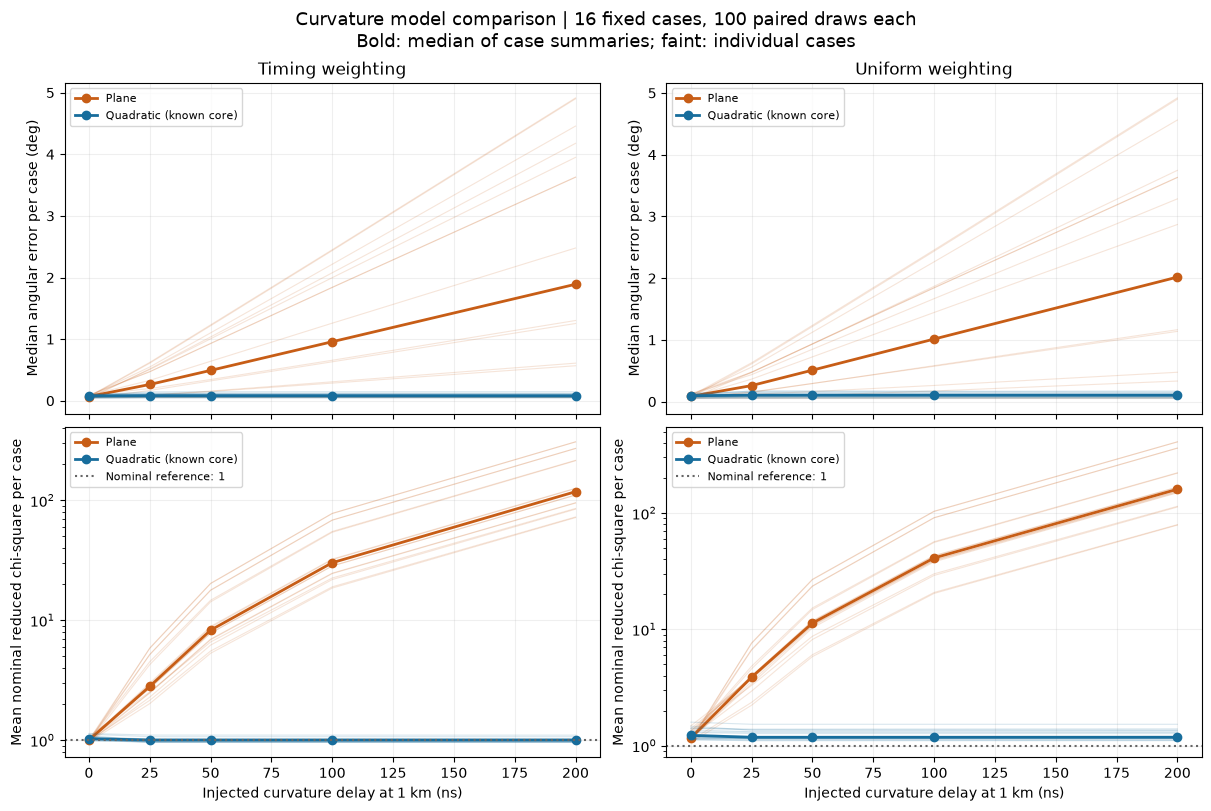

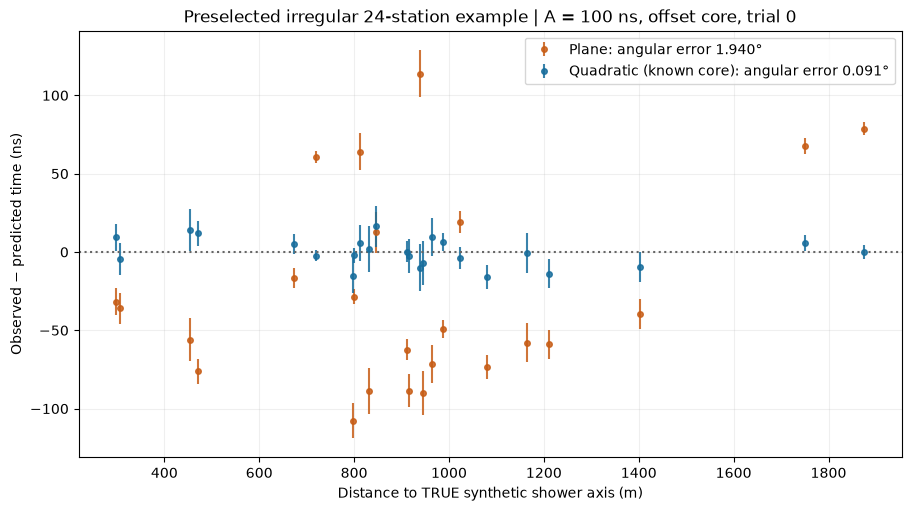

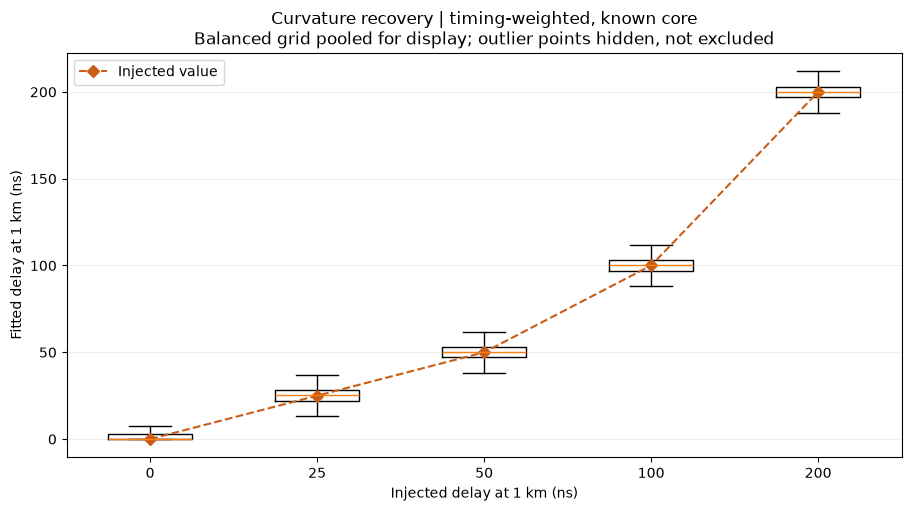

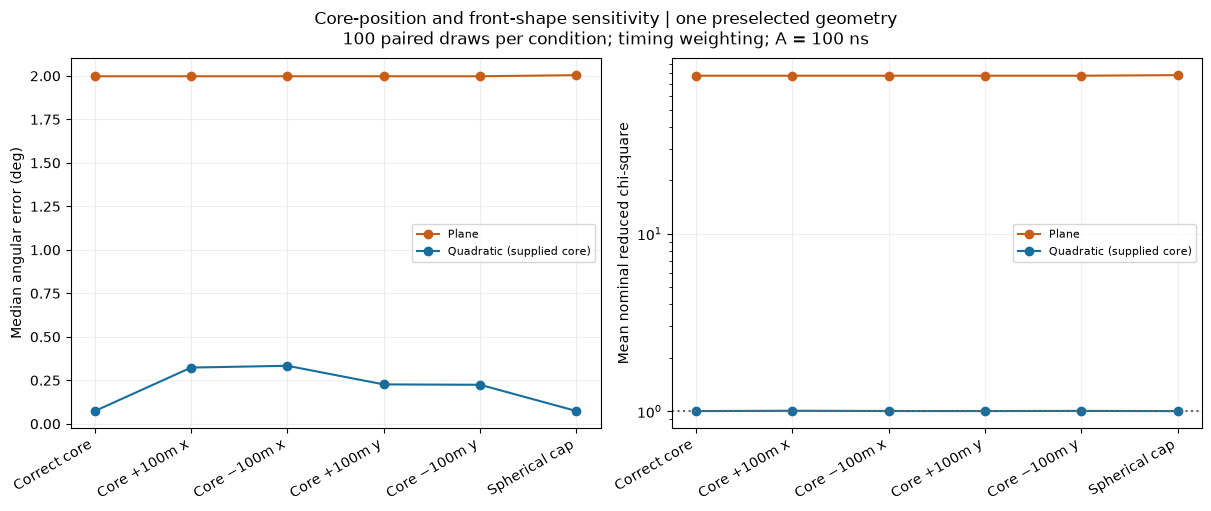

In [14]:
require_notebook_state(
    "Section 9",
    "method_summary",
    "stress_summary",
    "stress_data",
    "stress_conditions",
    "noise_archive",
)

COLORS = {"plane": "#C75D16", "quadratic": "#176D9C"}
LABELS = {"plane": "Plane", "quadratic": "Quadratic (known core)"}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained", sharex=True)
for column, weighting in enumerate(("timing", "uniform")):
    for row, metric in enumerate(("median_error_deg", "mean_nominal_reduced_chi_square")):
        ax = axes[row, column]
        for model in ("plane", "quadratic"):
            selected = method_summary.loc[
                (method_summary["weighting"] == weighting) & (method_summary["model"] == model)
            ]
            for _, group in selected.groupby("case_id"):
                group = group.sort_values("delay_at_1km_ns")
                ax.plot(
                    group["delay_at_1km_ns"],
                    group[metric],
                    color=COLORS[model],
                    alpha=0.16,
                    linewidth=0.8,
                )
            aggregate = selected.groupby("delay_at_1km_ns")[metric].median()
            ax.plot(
                aggregate.index,
                aggregate.values,
                "-o",
                color=COLORS[model],
                label=LABELS[model],
                linewidth=2,
            )
        ax.grid(alpha=0.2)
        if row == 0:
            ax.set_title(f"{weighting.capitalize()} weighting")
            ax.set_ylabel("Median angular error per case (deg)")
        else:
            ax.set_yscale("log")
            ax.axhline(1.0, color="0.4", linestyle=":", label="Nominal reference: 1")
            ax.set_ylabel("Mean nominal reduced chi-square per case")
            ax.set_xlabel("Injected curvature delay at 1 km (ns)")
        ax.legend(fontsize=8)
fig.suptitle(
    "Curvature model comparison | 16 fixed cases, 100 paired draws each\n"
    "Bold: median of case summaries; faint: individual cases",
    fontsize=13,
)
fig.savefig(RUN_DIR / "curvature_sensitivity.png", dpi=180)
plt.show()

example_observed = quadratic_exact + noise_archive[stress_case["case_id"]][0]
example_rows = []
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for model in ("plane", "quadratic"):
    row, _, fit = run_fit(
        stress_case,
        stress_data,
        example_observed,
        stress_delay,
        model,
        "timing",
        0,
        "preselected_plot",
    )
    if fit is None:
        raise RuntimeError("Preselected example failed; do not silently substitute another.")
    ax.errorbar(
        stress_data["rho"],
        fit.residuals_ns,
        yerr=stress_data["sigma"],
        fmt="o",
        markersize=4,
        alpha=0.85,
        color=COLORS[model],
        label=f"{LABELS[model]}: angular error {row['angular_error_deg']:.3f}°",
    )
    for station, (rho, observed, predicted, residual, sigma) in enumerate(
        zip(
            stress_data["rho"],
            example_observed,
            fit.predicted_times_ns,
            fit.residuals_ns,
            stress_data["sigma"],
            strict=True,
        )
    ):
        example_rows.append(
            {
                "model": model,
                "station": station,
                "true_rho_m": rho,
                "observed_ns": observed,
                "predicted_ns": predicted,
                "residual_ns": residual,
                "sigma_ns": sigma,
            }
        )
ax.axhline(0.0, color="0.4", linestyle=":")
ax.set(
    xlabel="Distance to TRUE synthetic shower axis (m)",
    ylabel="Observed − predicted time (ns)",
    title="Preselected irregular 24-station example | A = 100 ns, offset core, trial 0",
)
ax.grid(alpha=0.2)
ax.legend()
fig.savefig(RUN_DIR / "preselected_residual_comparison.png", dpi=180)
plt.show()
pd.DataFrame(example_rows).to_csv(RUN_DIR / "preselected_station_diagnostics.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
curved_valid = results.loc[
    results["success"] & (results["model"] == "quadratic") & (results["weighting"] == "timing")
]
groups = [
    curved_valid.loc[curved_valid["delay_at_1km_ns"] == level, "fitted_delay_at_1km_ns"]
    for level in CURVATURE_LEVELS_NS
]
ax.boxplot(groups, tick_labels=[f"{level:g}" for level in CURVATURE_LEVELS_NS], showfliers=False)
ax.plot(
    np.arange(1, len(CURVATURE_LEVELS_NS) + 1),
    CURVATURE_LEVELS_NS,
    "D--",
    color="#C75D16",
    label="Injected value",
)
ax.set(
    xlabel="Injected delay at 1 km (ns)",
    ylabel="Fitted delay at 1 km (ns)",
    title="Curvature recovery | timing-weighted, known core\n"
    "Balanced grid pooled for display; outlier points hidden, not excluded",
)
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.savefig(RUN_DIR / "curvature_recovery.png", dpi=180)
plt.show()

condition_labels = [item[0] for item in stress_conditions]
short_labels = [
    "Correct core",
    "Core +100m x",
    "Core −100m x",
    "Core +100m y",
    "Core −100m y",
    "Spherical cap",
]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for model in ("plane", "quadratic"):
    frame = stress_summary.xs(model, level="model").reindex(condition_labels)
    for ax, metric in zip(
        axes, ("median_error_deg", "mean_nominal_reduced_chi_square"), strict=True
    ):
        ax.plot(
            np.arange(len(frame)),
            frame[metric],
            "o-",
            color=COLORS[model],
            label="Plane" if model == "plane" else "Quadratic (supplied core)",
        )
        ax.set_xticks(np.arange(len(frame)), short_labels, rotation=30, ha="right")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
axes[0].set_ylabel("Median angular error (deg)")
axes[1].set_ylabel("Mean nominal reduced chi-square")
axes[1].set_yscale("log")
axes[1].axhline(1.0, color="0.4", linestyle=":")
fig.suptitle(
    "Core-position and front-shape sensitivity | one preselected geometry\n"
    "100 paired draws per condition; timing weighting; A = 100 ns"
)
fig.savefig(RUN_DIR / "core_and_shape_sensitivity.png", dpi=180)
plt.show()

## 10. Scientific conclusion and implementation requirements

The following conclusion is calculated from the saved results, not filled in with expected successes. It includes the zero-curvature control, numerical failures, unfavourable comparisons and stress tests.

Interpretation rules:

- Matched-model recovery verifies implementation. It is not a discovery or a realistic detector validation.
- A lower minimized objective is expected when adding an allowed parameter. Only the truth-based angular comparison establishes improved direction recovery here.
- Improvement is conditional on the specified core and scenario; do not generalize it to every geometry or real event.
- Boundary fits, uniform physical chi-square, and model-mismatched plane fits do not share the simple interior chi-square calibration.
- Before real-event use, core sourcing, core uncertainty, selection, and the still-unresolved coordinate-export detail must be addressed. Do not insert the official core or direction silently.
- Next: develop and validate the real-event core strategy, compare on the development event/small sample, then freeze the method before the larger cohort. This notebook does not change the production plane baseline.


In [15]:
require_notebook_state(
    "Section 10", "results", "stress_results", "paired_summary", "descriptive", "condition_labels"
)

failures = int((~results["success"]).sum())
stress_failures = int((~stress_results["success"]).sum())
positive_curvature_pairs = paired_summary.loc[
    (paired_summary["delay_at_1km_ns"] > 0) & (paired_summary["weighting"] == "timing")
]
negative_cases = int(
    (positive_curvature_pairs["median_paired_improvement_deg"] < -ANGLE_TOLERANCE_DEG).sum()
)
beneficial_cases = int(
    (positive_curvature_pairs["median_paired_improvement_deg"] > ANGLE_TOLERANCE_DEG).sum()
)
conclusion_lines = [
    "# Controlled-curvature experiment: scientific conclusion",
    "",
    f"Run: {RUN_DIR.name}",
    "",
    "## Design",
    "",
    "Sixteen fixed geometry/direction/core cases, five curvature levels, and "
    f"{TRIALS} Gaussian-noise draws per case produced {len(results) // 4:,} paired "
    f"synthetic datasets and {len(results):,} plane/quadratic, timing/uniform fit attempts. "
    "Four flat layouts were reused. The quadratic fitter was supplied the true core "
    "but not the true direction or curvature.",
    "",
    "## Verification and failures",
    "",
    f"- {len(exact_results)} noiseless fits completed successfully. The matching-model "
    "subset passed exact-recovery gates; the symmetric-plane parity control also passed.",
    f"- Main failed or invalid fits: {failures}/{len(results)}.",
    f"- Stress-study failed or invalid fits: {stress_failures}/{len(stress_results)}.",
    f"- Nested-objective violations: {len(nested_violations) + len(stress_violations)}.",
    "- Detailed optimizer attempts and failed outcomes are retained; summaries of errors "
    "are conditional on successful fits.",
    "",
    "## Main results",
    "",
    "These values are **medians across the 16 case-specific median angular errors**, "
    "not a population angular resolution. Chi-square values are means of case means.",
    "",
    "| A at 1 km (ns) | Plane median (deg) | Quadratic median (deg) | "
    "Plane nominal reduced chi-square | Quadratic nominal reduced chi-square |",
    "|---:|---:|---:|---:|---:|",
]
for level in CURVATURE_LEVELS_NS:
    plane_row = descriptive.loc[(level, "plane", "timing")]
    curved_row = descriptive.loc[(level, "quadratic", "timing")]
    conclusion_lines.append(
        f"| {level:g} | {plane_row['median_of_case_medians_deg']:.6f} | "
        f"{curved_row['median_of_case_medians_deg']:.6f} | "
        f"{plane_row['mean_of_case_mean_chi_square']:.4f} | "
        f"{curved_row['mean_of_case_mean_chi_square']:.4f} |"
    )
boundary = method_summary.loc[
    (method_summary["model"] == "quadratic")
    & (method_summary["weighting"] == "timing")
    & (method_summary["delay_at_1km_ns"] == 0),
    "curvature_boundary_fraction",
].mean()
conclusion_lines += [
    "",
    f"Among {len(positive_curvature_pairs)} positive-curvature, timing-weighted scenarios, "
    f"{beneficial_cases} had a positive median paired angular improvement and "
    f"{negative_cases} had a negative one beyond the {ANGLE_TOLERANCE_DEG:g} degree "
    "numerical tie threshold. These are descriptive counts, not multiple-testing-adjusted "
    "significance claims. Per-scenario paired bootstrap intervals are in paired_summary.csv.",
    "",
    f"At zero injected curvature, the mean boundary-fit fraction was {boundary:.3f} "
    f"using A <= {CURVATURE_TOLERANCE_NS:g} ns. Noise can produce positive fitted curvature "
    "even for planar data. The nominal N−4 denominator is not an exact boundary-law calibration.",
    "",
    "The symmetric, centred noiseless control retains direction accuracy while accumulating "
    "timing mismatch. Therefore, residual disagreement and directional accuracy must be "
    "reported separately.",
    "",
    "## Core and model-mismatch sensitivity",
    "",
    "| Condition | Plane median error (deg) | Quadratic median error (deg) | "
    "Quadratic nominal reduced chi-square |",
    "|---|---:|---:|---:|",
]
for label in condition_labels:
    plane_row = stress_summary.loc[(label, "plane")]
    curved_row = stress_summary.loc[(label, "quadratic")]
    conclusion_lines.append(
        f"| {label} | {plane_row['median_error_deg']:.6f} | "
        f"{curved_row['median_error_deg']:.6f} | "
        f"{curved_row['mean_nominal_reduced_chi_square']:.4f} |"
    )
conclusion_lines += [
    "",
    f"The translating-cap generator differed from the quadratic timing model by at most "
    f"{np.max(np.abs(cap_exact - quadratic_exact)):.4f} ns in the preselected example. "
    "This is one limited shape-mismatch test, not a full shower simulation. Core shifts "
    "of 100 m are sensitivity probes, not a claimed Auger uncertainty distribution.",
    "",
    "## Limitations and next requirements",
    "",
    "- The known-core assumption is an information advantage; independent core estimation "
    "and propagation of core uncertainty remain required.",
    "- Geometry and direction coverage is deliberately limited. The 100 draws per scenario "
    "leave p95 exploratory. The bootstrap reflects timing-noise sampling conditional on "
    "fixed cases, not realistic shower-to-shower uncertainty.",
    "- Gaussian independent noise with correctly specified uncertainties omits correlated "
    "timing, detector response, shower fluctuations, outliers and station selection.",
    "- No true-direction-dependent distance entered either optimization. Truth-derived "
    "distances appear only in generation, checks, and explicitly labelled diagnostic plots.",
    "- Do not call this a reduction of the measured event's chi-square or an improvement "
    "over Auger. Those real-data comparisons have not been performed here.",
    "- Preserve the plane baseline; validate the core strategy and additional failure modes "
    "before real-event curvature reconstruction and a frozen cohort study.",
    "",
    "Physics reference: [Auger, JINST 15 (2020) P10021, Section 5.1]"
    "(https://arxiv.org/pdf/2007.09035). The paraboloidal timing form is adapted; "
    "the complete Auger reconstruction is not reproduced.",
]
conclusion = "\n".join(conclusion_lines) + "\n"
(RUN_DIR / "scientific_conclusion.md").write_text(conclusion, encoding="utf-8")
save_json(
    "run_status.json",
    {
        "state": "complete",
        "main_fit_attempts": len(results),
        "main_failures": failures,
        "stress_fit_attempts": len(stress_results),
        "stress_failures": stress_failures,
        "exact_fit_attempts": len(exact_results),
        "runtime_seconds": time.perf_counter() - started,
    },
)
save_json(
    "artifact_hashes.json",
    {
        path.name: sha256(path.read_bytes()).hexdigest()
        for path in sorted(RUN_DIR.iterdir())
        if path.is_file()
    },
)
display(Markdown(conclusion))
print(f"All results saved: {RUN_DIR}")

# Controlled-curvature experiment: scientific conclusion

Run: synthetic_curvature_20261010T190421_183127Z

## Design

Sixteen fixed geometry/direction/core cases, five curvature levels, and 100 Gaussian-noise draws per case produced 8,000 paired synthetic datasets and 32,000 plane/quadratic, timing/uniform fit attempts. Four flat layouts were reused. The quadratic fitter was supplied the true core but not the true direction or curvature.

## Verification and failures

- 320 noiseless fits completed successfully. The matching-model subset passed exact-recovery gates; the symmetric-plane parity control also passed.
- Main failed or invalid fits: 0/32000.
- Stress-study failed or invalid fits: 0/1200.
- Nested-objective violations: 0.
- Detailed optimizer attempts and failed outcomes are retained; summaries of errors are conditional on successful fits.

## Main results

These values are **medians across the 16 case-specific median angular errors**, not a population angular resolution. Chi-square values are means of case means.

| A at 1 km (ns) | Plane median (deg) | Quadratic median (deg) | Plane nominal reduced chi-square | Quadratic nominal reduced chi-square |
|---:|---:|---:|---:|---:|
| 0 | 0.068358 | 0.076106 | 0.9959 | 1.0399 |
| 25 | 0.263781 | 0.081847 | 3.4994 | 1.0011 |
| 50 | 0.492048 | 0.081658 | 10.9650 | 1.0011 |
| 100 | 0.957538 | 0.080966 | 40.7821 | 1.0011 |
| 200 | 1.890178 | 0.079650 | 159.9603 | 1.0012 |

Among 64 positive-curvature, timing-weighted scenarios, 57 had a positive median paired angular improvement and 4 had a negative one beyond the 1e-05 degree numerical tie threshold. These are descriptive counts, not multiple-testing-adjusted significance claims. Per-scenario paired bootstrap intervals are in paired_summary.csv.

At zero injected curvature, the mean boundary-fit fraction was 0.482 using A <= 0.001 ns. Noise can produce positive fitted curvature even for planar data. The nominal N−4 denominator is not an exact boundary-law calibration.

The symmetric, centred noiseless control retains direction accuracy while accumulating timing mismatch. Therefore, residual disagreement and directional accuracy must be reported separately.

## Core and model-mismatch sensitivity

| Condition | Plane median error (deg) | Quadratic median error (deg) | Quadratic nominal reduced chi-square |
|---|---:|---:|---:|
| quadratic_correct_core | 1.997728 | 0.073034 | 1.0011 |
| quadratic_core_x_plus_100m | 1.997728 | 0.323222 | 1.0053 |
| quadratic_core_x_minus_100m | 1.997728 | 0.333606 | 1.0021 |
| quadratic_core_y_plus_100m | 1.997728 | 0.226551 | 1.0015 |
| quadratic_core_y_minus_100m | 1.997728 | 0.224386 | 1.0033 |
| spherical_cap_correct_core | 2.004168 | 0.073448 | 1.0008 |

The translating-cap generator differed from the quadratic timing model by at most 1.1188 ns in the preselected example. This is one limited shape-mismatch test, not a full shower simulation. Core shifts of 100 m are sensitivity probes, not a claimed Auger uncertainty distribution.

## Limitations and next requirements

- The known-core assumption is an information advantage; independent core estimation and propagation of core uncertainty remain required.
- Geometry and direction coverage is deliberately limited. The 100 draws per scenario leave p95 exploratory. The bootstrap reflects timing-noise sampling conditional on fixed cases, not realistic shower-to-shower uncertainty.
- Gaussian independent noise with correctly specified uncertainties omits correlated timing, detector response, shower fluctuations, outliers and station selection.
- No true-direction-dependent distance entered either optimization. Truth-derived distances appear only in generation, checks, and explicitly labelled diagnostic plots.
- Do not call this a reduction of the measured event's chi-square or an improvement over Auger. Those real-data comparisons have not been performed here.
- Preserve the plane baseline; validate the core strategy and additional failure modes before real-event curvature reconstruction and a frozen cohort study.

Physics reference: [Auger, JINST 15 (2020) P10021, Section 5.1](https://arxiv.org/pdf/2007.09035). The paraboloidal timing form is adapted; the complete Auger reconstruction is not reproduced.


All results saved: /home/abdul_samad/projects/auger-direction-reconstruction/reports/results/synthetic_curvature_20261010T190421_183127Z
